# 第16章 霍夫变换（跟随代码）

> 《OpenCV轻松入门：面向Python》第 16 章的跟随代码，内容未做改动。
> 运行前请确认工作目录为本文件夹（picture*.jpg 等素材都在这里）。

# 十六章 霍夫变换：在图像中寻找简单图形

## 霍夫直线变换


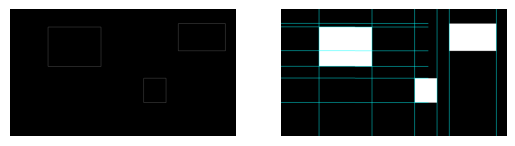

In [268]:
img=cv2.imread("picture9.jpg")
gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)

edges=cv2.Canny(gray,50,150,apertureSize=3)

orgb=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
oshow=orgb.copy()
lines=cv2.HoughLines(edges,1,np.pi/180,100)
for line in lines:
    rho,theta=line[0]
    a=np.cos(theta)
    b=np.sin(theta)
    x0=a*rho
    y0=b*rho
    x1=int(x0+1000*(-b))
    y1=int(y0+1000*(a))
    x2=int(x0-1000*(-b))
    y2=int(y0-1000*(a))
    cv2.line(orgb,(x1,y1),(x2,y2),(0,255,255),2)
plt.subplot(121)
plt.imshow(edges,cmap='gray')
plt.axis("off")
plt.subplot(122)
plt.imshow(orgb)
plt.axis("off")
plt.show()

## 概率霍夫直线变换


(np.float64(-0.5), np.float64(1039.5), np.float64(1386.5), np.float64(-0.5))

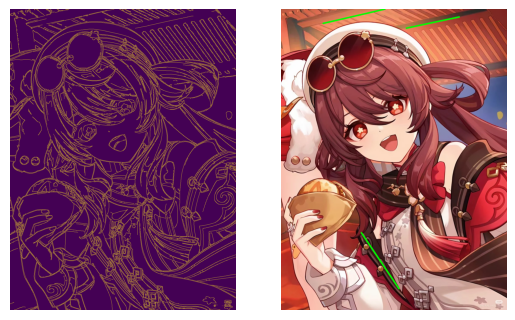

In [269]:
img=cv2.imread("picture2.png",-1)
gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)

edges=cv2.Canny(gray,50,150,apertureSize=3)

orgb=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

oshow=orgb.copy()

lines=cv2.HoughLinesP(edges,1,np.pi/180,threshold=100,minLineLength=200,maxLineGap=10)

for line in lines:
    x1,y1,x2,y2=line[0]
    cv2.line(orgb,(x1,y1),(x2,y2),(0,255,0),5)
plt.subplot(121),plt.imshow(edges)
plt.axis('off')
plt.subplot(122),plt.imshow(orgb)
plt.axis('off')

## 霍夫圆环变换


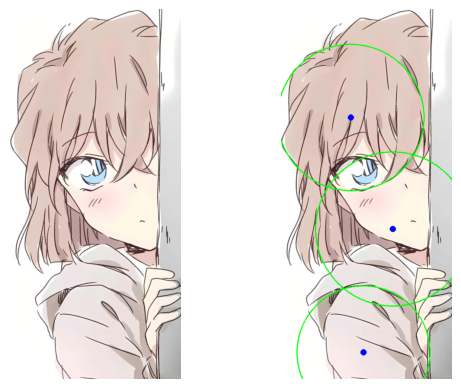

In [270]:
imgo=cv2.imread("picture8.jpg",-1)
img=cv2.cvtColor(imgo,cv2.COLOR_BGR2GRAY)
o=cv2.cvtColor(imgo,cv2.COLOR_BGR2RGB)
oshow=o.copy()
img=cv2.medianBlur(img,5)

circles=cv2.HoughCircles(img,cv2.HOUGH_GRADIENT,1,300,param1=50,param2=30,minRadius=100,maxRadius=200)

circles=np.uint16(np.around(circles))

for i in circles[0,:]:
    cv2.circle(o,(i[0],i[1]),i[2],(0,255,0),2)
    cv2.circle(o,(i[0],i[1]),2,(0,0,255),12)

plt.subplot(121)
plt.imshow(oshow)
plt.axis('off')
plt.subplot(122)
plt.imshow(o,cmap='gray')
plt.axis('off')
plt.show()
